# Phase 6 — Analytics Data Mart Exploration

**Project:** Telecom Customer Journey & Churn Root Cause Analysis Platform
**Phase:** 6 of 8 — Analytics Data Mart

This notebook explores the mart tables built by `analytics/build_mart.py`,
using DuckDB as the query engine — the same role Presto plays against
Iceberg tables in the operator's real stack. This notebook itself mirrors the operator's
Jupyter/Zeppelin exploration layer: ad-hoc analysis on top of a curated
mart, the step before a finding gets promoted into a permanent Superset
dashboard.

Run `python analytics/build_mart.py` first if `analytics_mart.duckdb`
doesn't exist yet.

## Setup

In [1]:
import duckdb
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.facecolor'] = 'white'

con = duckdb.connect("../data/processed/analytics_mart.duckdb", read_only=True)
print("Connected. Mart tables available:")
print(con.execute("SHOW TABLES").df())

Connected. Mart tables available:


                              name
0                     dim_customer
1                         dim_date
2                         dim_plan
3                       dim_region
4                   dim_root_cause
5     fact_customer_churn_snapshot
6             fact_network_tickets
7               mart_churn_by_plan
8             mart_churn_by_region
9                mart_customer_360
10  mart_network_root_cause_detail
11    mart_network_tickets_summary
12         mart_root_cause_summary


## Root cause distribution

This is the headline number for the whole platform: of every customer who
churned, what actually drove it? This is what a churn-save team budgets
against — for example, "81 network churns this period, is that worth a
tower investment?"

,root_cause_category,customer_count,pct_of_all_customers,pct_of_churned_only
0,active,4282,85.64,NaN
1,behavioral,587,11.74,81.75
2,network,81,1.62,11.28
3,mixed,50,1.00,6.96


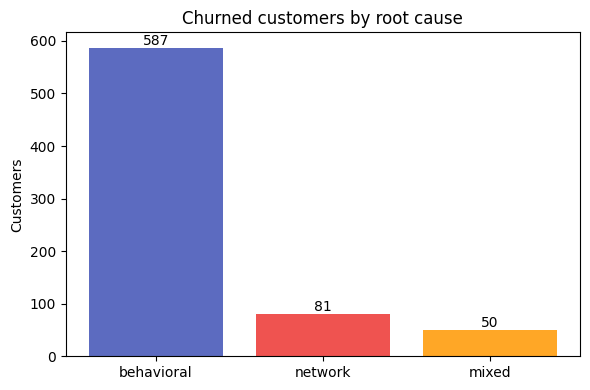

In [2]:
df_rc = con.execute("SELECT * FROM mart_root_cause_summary ORDER BY customer_count DESC").df()
display(df_rc)

churned = df_rc[df_rc["root_cause_category"] != "active"]
fig, ax = plt.subplots(figsize=(6, 4))
colors = {"behavioral": "#5C6BC0", "network": "#EF5350", "mixed": "#FFA726"}
ax.bar(churned["root_cause_category"], churned["customer_count"],
       color=[colors[c] for c in churned["root_cause_category"]])
ax.set_title("Churned customers by root cause")
ax.set_ylabel("Customers")
for i, v in enumerate(churned["customer_count"]):
    ax.text(i, v + 5, str(v), ha="center")
plt.tight_layout()
plt.show()

## Churn rate by region

Atbara shows the highest churn rate. Worth checking against
`mart_network_tickets_summary` below — is this region-level churn
network-driven, or behavioral?

,region_name,total_customers,churned_customers,churn_rate_pct,avg_monthly_arpu_sdg,avg_days_silent_churned
0,Atbara,286,52.0,18.18,1334.08,179.5
1,Omdurman,977,154.0,15.76,1499.38,181.0
2,El Obeid,359,56.0,15.60,1499.61,170.4
3,Khartoum,1771,267.0,15.08,1457.40,177.9
4,Kassala,405,52.0,12.84,1376.39,177.5
5,Wad Madani,419,53.0,12.65,1499.46,174.5
6,Nyala,354,40.0,11.30,1567.42,170.2
7,Port Sudan,429,44.0,10.26,1464.81,174.2


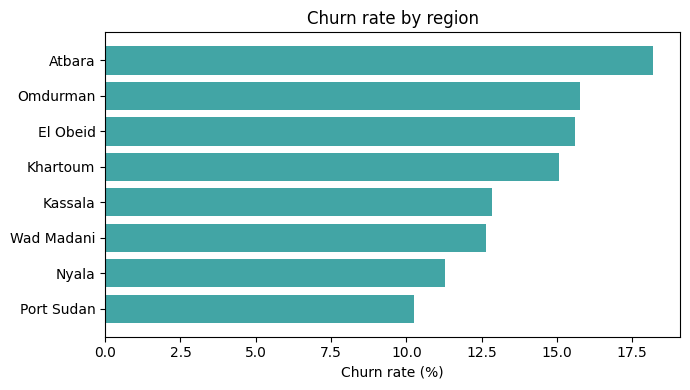

In [3]:
df_region = con.execute("SELECT * FROM mart_churn_by_region ORDER BY churn_rate_pct DESC").df()
display(df_region)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(df_region["region_name"][::-1], df_region["churn_rate_pct"][::-1], color="#42A5A5")
ax.set_xlabel("Churn rate (%)")
ax.set_title("Churn rate by region")
plt.tight_layout()
plt.show()

## Churn rate by plan type

Sudan's market is roughly 72% prepaid (see `run_phase1.py`'s `PLAN_WEIGHTS`)
— worth checking whether churn risk is concentrated there, since it's the
larger customer base.

,plan_type,total_customers,churned_customers,churn_rate_pct,avg_monthly_arpu_sdg
0,prepaid,3571,517.0,14.48,1450.97
1,postpaid,1429,201.0,14.07,1506.95


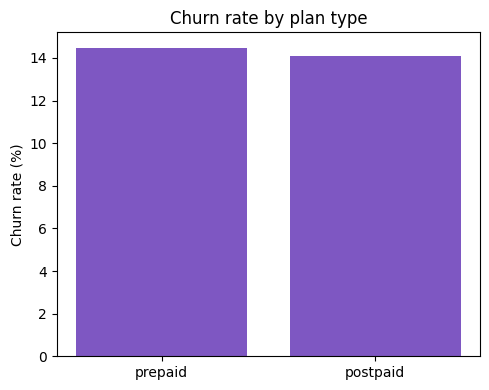

In [4]:
df_plan = con.execute("SELECT * FROM mart_churn_by_plan ORDER BY churn_rate_pct DESC").df()
display(df_plan)

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(df_plan["plan_type"], df_plan["churn_rate_pct"], color="#7E57C2")
ax.set_ylabel("Churn rate (%)")
ax.set_title("Churn rate by plan type")
plt.tight_layout()
plt.show()

## Network ticket resolution by issue type

This view is NOT filtered to churned customers — it's an operational view
for the NOC team on ticket-handling quality across everyone, regardless of
whether they ultimately churned.

,issue_type,ticket_count,resolution_rate_pct
0,dropped_call,700.0,75.1
1,no_signal,664.0,75.0
2,roaming_issue,383.0,75.5
3,slow_data,330.0,75.2
4,sms_failure,326.0,69.9


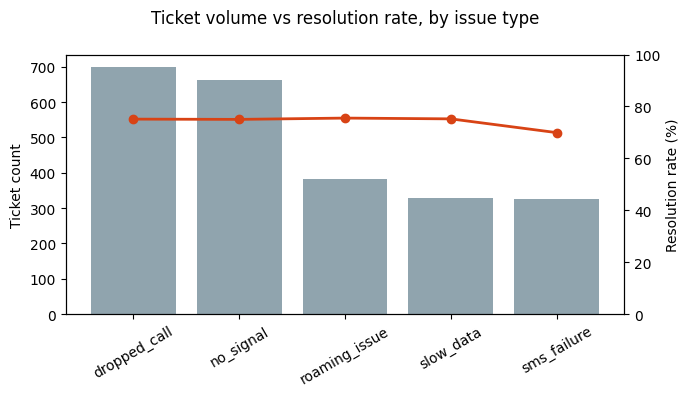

In [5]:
df_tix = con.execute("""
    SELECT issue_type,
           SUM(ticket_count) AS ticket_count,
           ROUND(100.0 * SUM(resolved_count) / SUM(ticket_count), 1) AS resolution_rate_pct
    FROM mart_network_tickets_summary
    GROUP BY issue_type
    ORDER BY ticket_count DESC
""").df()
display(df_tix)

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.bar(df_tix["issue_type"], df_tix["ticket_count"], color="#90A4AE", label="Ticket count")
ax1.set_ylabel("Ticket count")
ax1.tick_params(axis='x', rotation=30)

ax2 = ax1.twinx()
ax2.plot(df_tix["issue_type"], df_tix["resolution_rate_pct"], color="#D84315",
         marker="o", linewidth=2, label="Resolution rate %")
ax2.set_ylabel("Resolution rate (%)")
ax2.set_ylim(0, 100)

fig.suptitle("Ticket volume vs resolution rate, by issue type")
fig.tight_layout()
plt.show()

## Drill-down: tickets behind a network-classified churn

`root_cause_engine.py` labels a customer "network" or "mixed" from a
threshold rule (3+ tickets in the 30 days before going silent). This view
shows the literal ticket records behind that label for one example
customer — the explainability payoff the rule engine is designed for: not
just a category, but the evidence a NOC analyst could open and verify.

In [6]:
example_customer = con.execute("""
    SELECT customer_id FROM mart_network_root_cause_detail
    GROUP BY customer_id
    ORDER BY COUNT(*) DESC
    LIMIT 1
""").fetchone()[0]

print(f"Example customer: {example_customer}")
df_detail = con.execute(f"""
    SELECT * FROM mart_network_root_cause_detail
    WHERE customer_id = '{example_customer}'
    ORDER BY ticket_date
""").df()
display(df_detail)

Example customer: C000020


,customer_id,region_name,root_cause_category,classification_reason,tickets_last_30d_before_silence,ticket_id,issue_type,status,resolution_days,ticket_date
0,C000020,Khartoum,mixed,Mixed - 5 network tickets AND 2 unpaid months,5,TKT0000010,no_signal,in_progress,NaN,2024-06-22
1,C000020,Khartoum,mixed,Mixed - 5 network tickets AND 2 unpaid months,5,TKT0000011,no_signal,closed,13.0,2024-07-02
2,C000020,Khartoum,mixed,Mixed - 5 network tickets AND 2 unpaid months,5,TKT0000012,dropped_call,resolved,7.0,2024-07-02
3,C000020,Khartoum,mixed,Mixed - 5 network tickets AND 2 unpaid months,5,TKT0000008,dropped_call,open,NaN,2024-07-04
4,C000020,Khartoum,mixed,Mixed - 5 network tickets AND 2 unpaid months,5,TKT0000009,dropped_call,closed,7.0,2024-07-19


## Close the connection

In [7]:
con.close()